# Plantiful offline pilot training

This notebook trains a first offline plant classifier from the candidate metadata in `Ai/datasets/pilot-candidates.jsonl`.

It does not assume the candidate labels are expert verified. The images are research-grade iNaturalist observations with CC0, CC BY or CC BY-SA photo licences. The notebook downloads only the selected candidates, deduplicates by SHA256, splits by observation, fine-tunes MobileNetV3-Small and records honest test metrics.

Outputs stay inside the project:

- Images: `Ai/datasets/raw/pilot/` (ignored by Git)
- Model binaries: `Ai/models/pilot/` (ignored by Git)
- Metrics and review evidence: `Ai/evaluation/pilot/`
- Self-contained notebook: `Ai/a.ipynb`

Set `PLANTIFUL_SMOKE=1` before execution to run a small one-epoch pipeline check. Normal execution trains the full pilot set.

Important limits:

- This is a 20-species convenience pilot, not the full 263-species catalogue.
- Research grade is community consensus, not independent ground truth.
- There is no unknown-class calibration yet.
- No accuracy result may be presented as field performance until local photos are tested.


In [1]:
import hashlib
import json
import os
import random
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small
from tqdm.auto import tqdm

SEED = 42
SMOKE = os.environ.get("PLANTIFUL_SMOKE") == "1"
EPOCHS = 1 if SMOKE else 12
BATCH_SIZE = 32 if SMOKE else 64
IMG_SIZE = 224
LR = 2e-4
WEIGHT_DECAY = 1e-4
MAX_PER_CLASS = 8 if SMOKE else None
NUM_WORKERS = 0
PATIENCE = 2 if SMOKE else 4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = DEVICE.type == "cuda"

print("Device:", DEVICE)
print("Smoke mode:", SMOKE)
print("Epochs:", EPOCHS)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


ModuleNotFoundError: No module named 'torch'

In [ ]:
PROJECT_ROOT = Path.cwd()
manifest_path = PROJECT_ROOT / "Ai" / "datasets" / "pilot-candidates.jsonl"
if not manifest_path.exists():
    candidate = PROJECT_ROOT.parent / "Ai" / "datasets" / "pilot-candidates.jsonl"
    if candidate.exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
        manifest_path = candidate
if not manifest_path.exists():
    raise FileNotFoundError("Run this notebook from the project root or from the Ai folder.")

RAW_DIR = PROJECT_ROOT / "Ai" / "datasets" / "raw" / "pilot"
MODEL_DIR = PROJECT_ROOT / "Ai" / "models" / "pilot"
EVAL_DIR = PROJECT_ROOT / "Ai" / "evaluation" / "pilot"
for directory in (RAW_DIR, MODEL_DIR, EVAL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Manifest:", manifest_path)
print("Raw images:", RAW_DIR)
print("Model artifacts:", MODEL_DIR)
print("Evaluation evidence:", EVAL_DIR)


Project root: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30049 COMPUTING TECHNOLOGY INNOVATION PROJECT\Project\COS30049_InnovationProject_Plantiful
Manifest: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30049 COMPUTING TECHNOLOGY INNOVATION PROJECT\Project\COS30049_InnovationProject_Plantiful\Ai\datasets\pilot-candidates.jsonl
Raw images: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30049 COMPUTING TECHNOLOGY INNOVATION PROJECT\Project\COS30049_InnovationProject_Plantiful\Ai\datasets\raw\pilot
Model artifacts: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30049 COMPUTING TECHNOLOGY INNOVATION PROJECT\Project\COS30049_InnovationProject_Plantiful\Ai\models\pilot
Evaluation evidence: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30049 COMPUTING TECHNOLOGY INNOVATION PROJECT\Project\COS30049_InnovationProject_Plantiful\Ai\evaluation\pilot


In [ ]:
manifest = pd.read_json(manifest_path, lines=True)
required = {"catalogue_name", "observation_id", "photo_id", "image_url", "licence", "attribution"}
missing = required.difference(manifest.columns)
if missing:
    raise ValueError(f"Manifest is missing columns: {sorted(missing)}")

manifest = manifest.dropna(subset=["catalogue_name", "observation_id", "photo_id", "image_url"]).copy()
manifest["catalogue_name"] = manifest["catalogue_name"].astype(str).str.strip()
manifest = manifest.drop_duplicates(subset=["photo_id"]).copy()

labels = sorted(manifest["catalogue_name"].unique().tolist())
label_to_index = {name: index for index, name in enumerate(labels)}
if MAX_PER_CLASS is not None:
    manifest = manifest.groupby("catalogue_name", group_keys=False).head(MAX_PER_CLASS).copy()

print(f"Manifest rows: {len(manifest)}")
print(f"Classes: {len(labels)}")
print(manifest.groupby("catalogue_name").size().to_string())


Manifest rows: 1964
Classes: 20
catalogue_name
Acacia auriculiformis      100
Acacia mangium             100
Antigonon leptopus         100
Arundina graminifolia      100
Casuarina equisetifolia    100
Chromolaena odorata        100
Clitoria ternatea           96
Dicranopteris linearis      99
Etlingera elatior          100
Hibiscus tiliaceus          88
Lantana camara              97
Melastoma malabathricum     87
Mimosa pudica              100
Morinda citrifolia         100
Peperomia pellucida        100
Pteris vittata             100
Scaevola taccada            97
Senna alata                100
Sphagneticola trilobata    100
Terminalia catappa         100


In [ ]:
SESSION_HEADERS = {"User-Agent": "Plantiful offline pilot (student research project)"}
ALLOWED_HOSTS = {"inaturalist-open-data.s3.amazonaws.com", "static.inaturalist.org"}


def slug(value):
    return "".join(character if character.isalnum() else "_" for character in value.lower()).strip("_")


def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def allowed_url(url):
    parsed = urlparse(url)
    return parsed.scheme == "https" and parsed.hostname in ALLOWED_HOSTS


def download(row):
    url = row["image_url"]
    if not allowed_url(url):
        return {**row, "local_path": None, "sha256": None, "bytes": None, "error": "unexpected_url"}
    destination = RAW_DIR / slug(row["catalogue_name"]) / f"{int(row['photo_id'])}.jpg"
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        try:
            with Image.open(destination) as image:
                image.verify()
            return {**row, "local_path": str(destination), "sha256": sha256(destination), "bytes": destination.stat().st_size, "error": None}
        except Exception:
            destination.unlink(missing_ok=True)

    last_error = None
    for attempt in range(3):
        try:
            response = requests.get(url, headers=SESSION_HEADERS, timeout=30)
            if response.status_code in (429, 500, 502, 503, 504):
                last_error = f"http_{response.status_code}"
                time.sleep(2 * (attempt + 1))
                continue
            response.raise_for_status()
            if len(response.content) > 10_000_000:
                raise ValueError("image_too_large")
            temporary = destination.with_suffix(".part")
            temporary.write_bytes(response.content)
            with Image.open(temporary) as image:
                image.verify()
            with Image.open(temporary) as image:
                if min(image.size) < 100:
                    raise ValueError("image_too_small")
                image.convert("RGB")
            temporary.replace(destination)
            return {**row, "local_path": str(destination), "sha256": sha256(destination), "bytes": destination.stat().st_size, "error": None}
        except Exception as error:
            last_error = type(error).__name__
            if attempt < 2:
                time.sleep(1 + attempt)
    return {**row, "local_path": None, "sha256": None, "bytes": None, "error": last_error}


downloaded = []
failed = []
with ThreadPoolExecutor(max_workers=8) as pool:
    futures = [pool.submit(download, row) for row in manifest.to_dict("records")]
    for future in tqdm(as_completed(futures), total=len(futures), desc="Downloading"):
        result = future.result()
        if result["local_path"]:
            downloaded.append(result)
        else:
            failed.append(result)

images = pd.DataFrame(downloaded)
if images.empty:
    raise RuntimeError("No candidate images downloaded.")
images = images.drop_duplicates(subset=["sha256"], keep="first").copy()
images["label"] = images["catalogue_name"].map(label_to_index)
images.to_csv(RAW_DIR / "downloaded.csv", index=False)
pd.DataFrame(failed).to_csv(RAW_DIR / "download_failures.csv", index=False)

print(f"Unique downloaded images: {len(images)}")
print(f"Failed or rejected: {len(failed)}")
if failed:
    print(pd.DataFrame(failed)["error"].value_counts().to_string())


Downloading:   0%|          | 0/1964 [00:00<?, ?it/s]

Unique downloaded images: 1954
Failed or rejected: 0


In [ ]:
images["observation_id"] = images["observation_id"].astype(str)
parts = []
for label_value, group in images.groupby("label"):
    observations = sorted(group["observation_id"].unique().tolist())
    rng = random.Random(SEED + int(label_value))
    rng.shuffle(observations)
    count = len(observations)
    if count < 3:
        raise ValueError(f"Not enough observations for {labels[int(label_value)]}")
    train_count = max(1, int(round(count * 0.70)))
    validation_count = max(1, int(round(count * 0.15)))
    if train_count + validation_count >= count:
        train_count = count - 2
        validation_count = 1
    train_observations = set(observations[:train_count])
    validation_observations = set(observations[train_count:train_count + validation_count])
    test_observations = set(observations[train_count + validation_count:])
    if not test_observations:
        raise ValueError("Empty test split")
    group = group.copy()
    group["split"] = group["observation_id"].map(
        lambda value: "train" if value in train_observations else "val" if value in validation_observations else "test"
    )
    parts.append(group)

images = pd.concat(parts, ignore_index=True)
images.to_csv(RAW_DIR / "splits.csv", index=False)
images.to_csv(EVAL_DIR / "dataset_manifest.csv", index=False)
with open(EVAL_DIR / "labels.json", "w", encoding="utf-8") as handle:
    json.dump({"labels": labels, "label_to_index": label_to_index}, handle, indent=2)

print(images.groupby("split").size().to_string())
print(images.groupby(["catalogue_name", "split"]).size().unstack(fill_value=0).to_string())


split
test      293
train    1367
val       294
split                    test  train  val
catalogue_name                           
Acacia auriculiformis      15     70   15
Acacia mangium             15     70   15
Antigonon leptopus         14     69   15
Arundina graminifolia      15     70   15
Casuarina equisetifolia    15     70   15
Chromolaena odorata        15     70   15
Clitoria ternatea          15     66   14
Dicranopteris linearis     15     69   15
Etlingera elatior          15     70   15
Hibiscus tiliaceus         13     62   13
Lantana camara             14     68   15
Melastoma malabathricum    13     61   13
Mimosa pudica              15     69   15
Morinda citrifolia         15     70   15
Peperomia pellucida        15     70   15
Pteris vittata             14     68   15
Scaevola taccada           15     67   14
Senna alata                15     70   15
Sphagneticola trilobata    15     69   15
Terminalia catappa         15     69   15


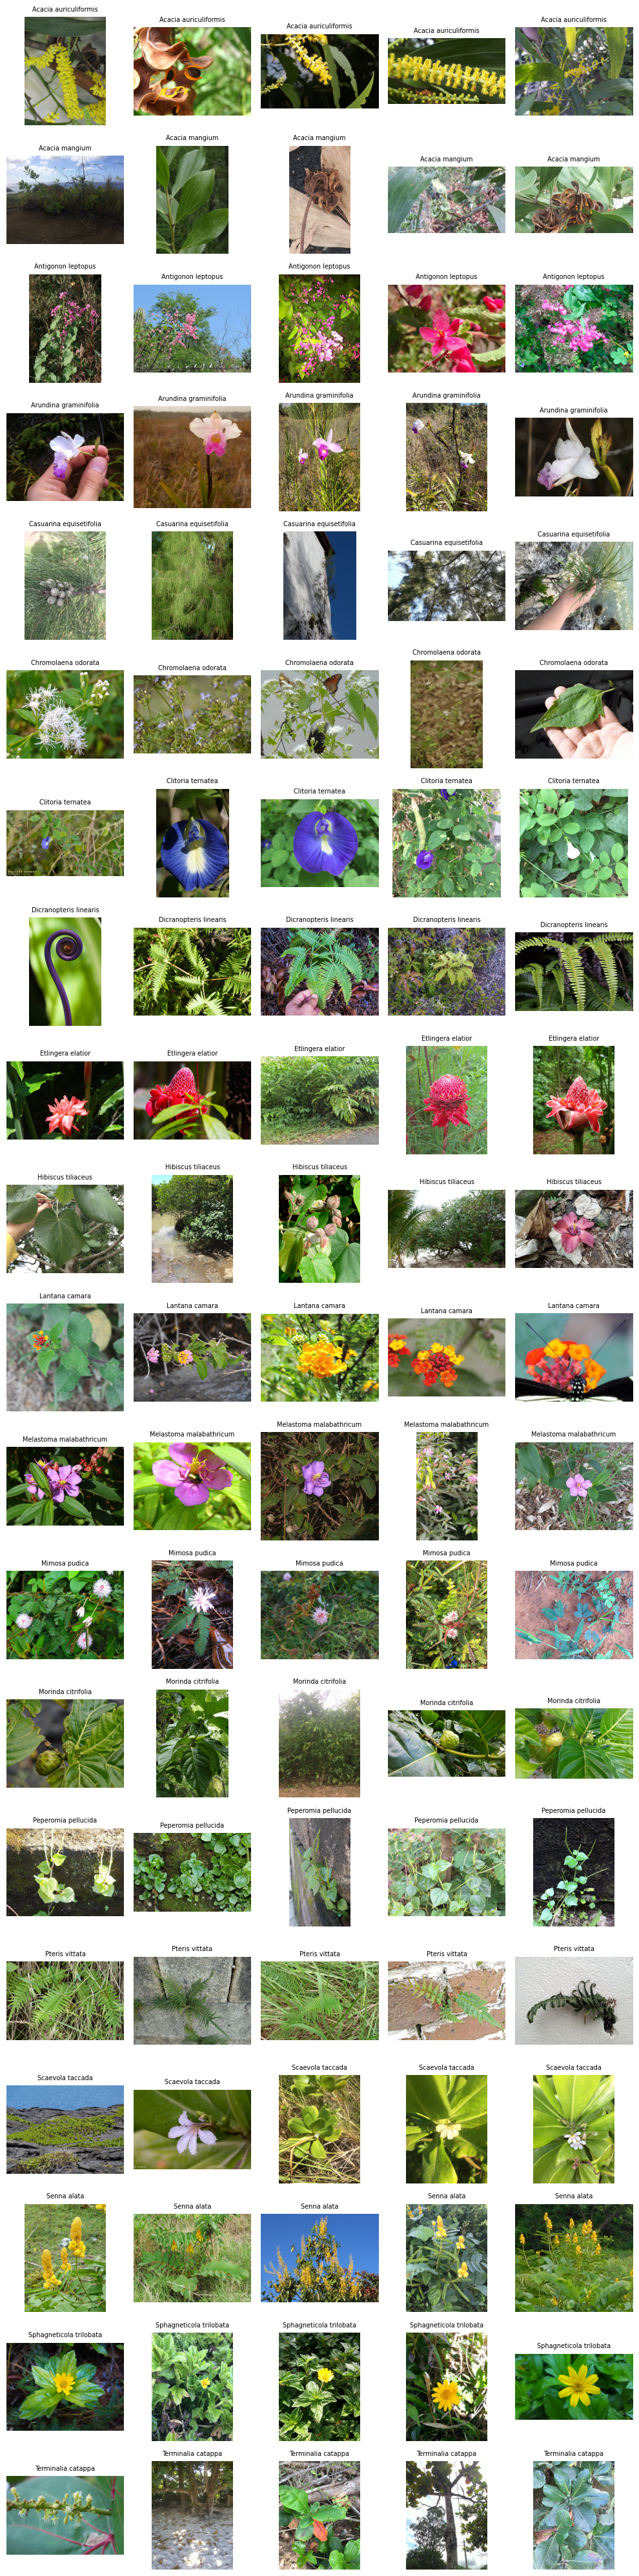

Review grid: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30049 COMPUTING TECHNOLOGY INNOVATION PROJECT\Project\COS30049_InnovationProject_Plantiful\Ai\evaluation\pilot\review_grid.png


In [ ]:
review_images = images[images["split"] == "train"]
class_values = sorted(review_images["label"].unique().tolist())
per_class = 5
figure, axes = plt.subplots(len(class_values), per_class, figsize=(per_class * 2, len(class_values) * 2))
axes = np.atleast_2d(axes)
for row_index, label_value in enumerate(class_values):
    sample = review_images[review_images["label"] == label_value].head(per_class)
    for column_index in range(per_class):
        axis = axes[row_index, column_index]
        axis.axis("off")
        if column_index < len(sample):
            item = sample.iloc[column_index]
            with Image.open(item["local_path"]) as image:
                axis.imshow(ImageOps.exif_transpose(image).convert("RGB"))
            axis.set_title(labels[int(label_value)], fontsize=7)
figure.tight_layout()
figure.savefig(EVAL_DIR / "review_grid.png", dpi=120, bbox_inches="tight")
plt.show()
print("Review grid:", EVAL_DIR / "review_grid.png")


In [ ]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.70, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.20, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
evaluation_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


class PlantDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["local_path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            tensor = self.transform(image)
        return tensor, int(row["label"])


train_frame = images[images["split"] == "train"].copy()
validation_frame = images[images["split"] == "val"].copy()
test_frame = images[images["split"] == "test"].copy()
if train_frame.empty or validation_frame.empty or test_frame.empty:
    raise ValueError("One or more splits are empty.")

train_loader = DataLoader(PlantDataset(train_frame, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
validation_loader = DataLoader(PlantDataset(validation_frame, evaluation_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
test_loader = DataLoader(PlantDataset(test_frame, evaluation_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")

print(f"Train: {len(train_frame)} | Validation: {len(validation_frame)} | Test: {len(test_frame)}")


Train: 1367 | Validation: 294 | Test: 293


In [ ]:
model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
input_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(input_features, len(labels))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, EPOCHS))
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

print(model.classifier)


Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=20, bias=True)
)


In [ ]:
def topk_accuracy(logits, targets, k):
    selected = logits.topk(k, dim=1).indices
    return (selected == targets.unsqueeze(1)).any(dim=1).float().mean().item()


def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    total_top1 = 0.0
    total_top3 = 0.0
    total = 0
    for inputs, targets in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(inputs)
                loss = criterion(logits, targets)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        batch_size = targets.size(0)
        total += batch_size
        total_loss += loss.item() * batch_size
        total_top1 += topk_accuracy(logits.detach(), targets, 1) * batch_size
        total_top3 += topk_accuracy(logits.detach(), targets, 3) * batch_size
    return total_loss / total, total_top1 / total, total_top3 / total


history = []
best_validation_top1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    started = time.time()
    train_loss, train_top1, train_top3 = run_epoch(train_loader, True)
    validation_loss, validation_top1, validation_top3 = run_epoch(validation_loader, False)
    scheduler.step()
    elapsed = time.time() - started
    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_top1": train_top1,
        "train_top3": train_top3,
        "validation_loss": validation_loss,
        "validation_top1": validation_top1,
        "validation_top3": validation_top3,
        "seconds": elapsed,
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(row)
    print(f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f} top1 {train_top1:.3f} | val loss {validation_loss:.4f} top1 {validation_top1:.3f} | {elapsed:.1f}s")

    if validation_top1 > best_validation_top1:
        best_validation_top1 = validation_top1
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save({
            "model": model.state_dict(),
            "labels": labels,
            "config": {
                "image_size": IMG_SIZE,
                "mean": MEAN,
                "std": STD,
                "seed": SEED,
                "epoch": epoch,
                "validation_top1": validation_top1,
            },
        }, MODEL_DIR / "best.pt")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

pd.DataFrame(history).to_csv(EVAL_DIR / "training_history.csv", index=False)
print(f"Best epoch: {best_epoch} | validation top1: {best_validation_top1:.3f}")


Epoch 1/12 | train loss 2.8201 top1 0.213 | val loss 2.5720 top1 0.374 | 59.6s


Epoch 2/12 | train loss 2.1503 top1 0.553 | val loss 2.0619 top1 0.480 | 53.8s


Epoch 3/12 | train loss 1.5998 top1 0.697 | val loss 1.8221 top1 0.541 | 49.2s


Epoch 4/12 | train loss 1.3453 top1 0.761 | val loss 1.6167 top1 0.619 | 46.9s


Epoch 5/12 | train loss 1.1998 top1 0.802 | val loss 1.5021 top1 0.663 | 48.3s


Epoch 6/12 | train loss 1.1107 top1 0.847 | val loss 1.4105 top1 0.711 | 45.7s


... (2 outputs left out)

Epoch 9/12 | train loss 0.9683 top1 0.901 | val loss 1.3088 top1 0.745 | 38.1s


Epoch 10/12 | train loss 0.9539 top1 0.908 | val loss 1.2925 top1 0.762 | 56.0s


Epoch 11/12 | train loss 0.9530 top1 0.904 | val loss 1.2854 top1 0.765 | 54.2s


Epoch 12/12 | train loss 0.9398 top1 0.916 | val loss 1.2804 top1 0.769 | 47.2s
Best epoch: 12 | validation top1: 0.769


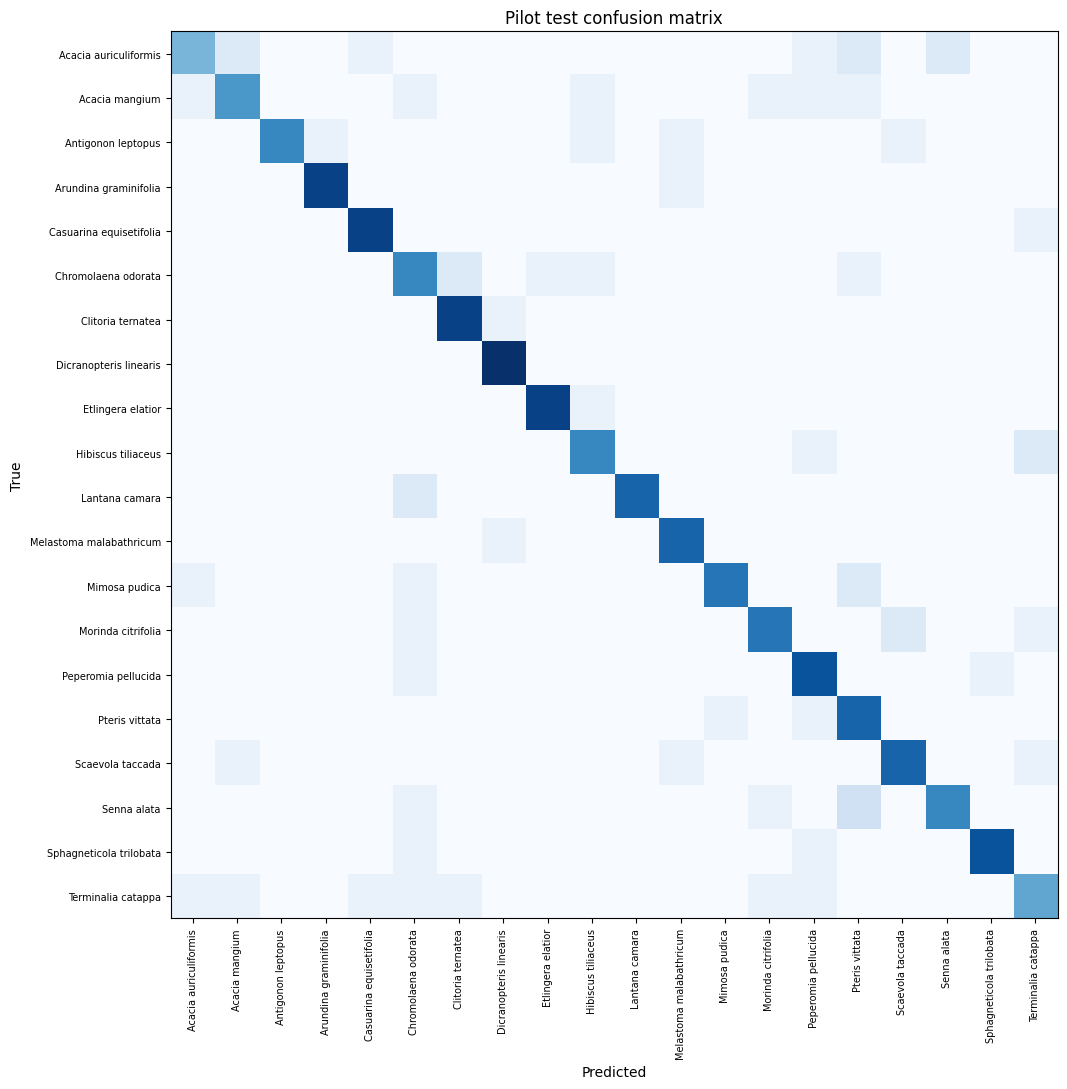

Test top1: 0.788 | Test top3: 0.918
Test images: 293


In [ ]:
checkpoint = torch.load(MODEL_DIR / "best.pt", map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model"])
model.eval()

all_targets = []
all_predictions = []
all_probabilities = []
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        logits = model(inputs)
        probabilities = torch.softmax(logits.float(), dim=1).cpu()
        all_probabilities.append(probabilities)
        all_predictions.extend(probabilities.argmax(dim=1).tolist())
        all_targets.extend(targets.tolist())

all_probabilities = torch.cat(all_probabilities, dim=0).numpy()
all_targets = np.array(all_targets)
all_predictions = np.array(all_predictions)
top1 = float((all_predictions == all_targets).mean())
top3 = float(np.mean([all_targets[index] in np.argsort(all_probabilities[index])[-3:] for index in range(len(all_targets))]))

report = classification_report(
    all_targets,
    all_predictions,
    labels=list(range(len(labels))),
    target_names=labels,
    output_dict=True,
    zero_division=0,
)
matrix = confusion_matrix(all_targets, all_predictions, labels=list(range(len(labels))))

pd.DataFrame(report).transpose().to_csv(EVAL_DIR / "classification_report.csv")
pd.DataFrame(matrix, index=labels, columns=labels).to_csv(EVAL_DIR / "confusion_matrix.csv")

figure, axis = plt.subplots(figsize=(13, 11))
axis.imshow(matrix, cmap="Blues")
axis.set_title("Pilot test confusion matrix")
axis.set_xlabel("Predicted")
axis.set_ylabel("True")
axis.set_xticks(range(len(labels)))
axis.set_yticks(range(len(labels)))
axis.set_xticklabels(labels, rotation=90, fontsize=7)
axis.set_yticklabels(labels, fontsize=7)
figure.tight_layout()
figure.savefig(EVAL_DIR / "confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

metrics = {
    "test_images": int(len(all_targets)),
    "classes": len(labels),
    "top1": top1,
    "top3": top3,
    "per_class_recall": {labels[index]: float(matrix[index, index] / max(1, matrix[index].sum())) for index in range(len(labels))},
    "report": report,
    "confusion_matrix": matrix.tolist(),
    "best_epoch": best_epoch,
    "validation_top1": best_validation_top1,
    "dataset": "iNaturalist research-grade candidate photos, automatic licence filtering, labels not manually verified",
}
with open(EVAL_DIR / "metrics.json", "w", encoding="utf-8") as handle:
    json.dump(metrics, handle, indent=2, default=lambda value: value.item() if hasattr(value, "item") else str(value))

print(f"Test top1: {top1:.3f} | Test top3: {top3:.3f}")
print(f"Test images: {len(all_targets)}")


In [ ]:
model = model.cpu().eval()
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
onnx_path = MODEL_DIR / "mobilenetv3_small.onnx"
onnx_status = "not_exported"
try:
    import onnx  # noqa: F401

    torch.onnx.export(
        model,
        dummy,
        onnx_path,
        input_names=["input"],
        output_names=["logits"],
        dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
        opset_version=17,
    )
    onnx_status = "exported"
except Exception as error:
    onnx_status = f"skipped: {type(error).__name__}: {error}"
    if onnx_path.exists():
        onnx_path.unlink()

traced = torch.jit.trace(model, dummy)
traced_path = MODEL_DIR / "mobilenetv3_small_traced.pt"
traced.save(traced_path)

artifacts = {
    "checkpoint": str(MODEL_DIR / "best.pt"),
    "torchscript": str(traced_path),
}
if onnx_path.exists():
    artifacts["onnx"] = str(onnx_path)

model_card = {
    "model": "mobilenet_v3_small",
    "pretraining": "ImageNet IMAGENET1K_V1",
    "input": {"shape": [1, 3, IMG_SIZE, IMG_SIZE], "mean": MEAN, "std": STD, "colour_order": "RGB"},
    "preprocessing": "Resize shorter side to 256, centre crop 224 for evaluation. Random resized crop and augmentation for training.",
    "classes": labels,
    "training_scope": f"{len(labels)} candidate pilot species, not the full catalogue",
    "dataset": "iNaturalist research-grade candidate photos with CC0, CC BY or CC BY-SA licences. Automatic filters only. Labels not manually verified.",
    "seed": SEED,
    "epochs_planned": EPOCHS,
    "epochs_completed": len(history),
    "batch_size": BATCH_SIZE,
    "learning_rate": LR,
    "best_epoch": best_epoch,
    "validation_top1": best_validation_top1,
    "test_top1": top1,
    "test_top3": top3,
    "onnx_status": onnx_status,
    "artifacts": artifacts,
    "limitations": "Pilot only. No unknown-class calibration. No field-photo domain-shift result. Not a production accuracy claim.",
}
with open(EVAL_DIR / "model_card.json", "w", encoding="utf-8") as handle:
    json.dump(model_card, handle, indent=2)
model.to(DEVICE)

print("ONNX status:", onnx_status)
print("TorchScript:", traced_path, f"{traced_path.stat().st_size / 1024 / 1024:.2f} MB")
print("Model card:", EVAL_DIR / "model_card.json")


ONNX status: skipped: ModuleNotFoundError: No module named 'onnx.defs'
TorchScript: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30049 COMPUTING TECHNOLOGY INNOVATION PROJECT\Project\COS30049_InnovationProject_Plantiful\Ai\models\pilot\mobilenetv3_small_traced.pt 6.35 MB
Model card: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30049 COMPUTING TECHNOLOGY INNOVATION PROJECT\Project\COS30049_InnovationProject_Plantiful\Ai\evaluation\pilot\model_card.json


In [ ]:
samples = test_frame.sample(n=min(5, len(test_frame)), random_state=SEED)
sample_results = []
model.eval()
for _, row in samples.iterrows():
    with Image.open(row["local_path"]) as image:
        tensor = evaluation_transform(ImageOps.exif_transpose(image).convert("RGB")).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probabilities = torch.softmax(model(tensor).float(), dim=1).cpu().numpy()[0]
    order = np.argsort(probabilities)[::-1][:3]
    result = {
        "true": labels[int(row["label"])],
        "image": row["local_path"],
        "top3": [{"label": labels[int(index)], "score": float(probabilities[int(index)])} for index in order],
    }
    sample_results.append(result)
    print(result["true"], "->", [(item["label"], round(item["score"], 3)) for item in result["top3"]])

with open(EVAL_DIR / "sample_predictions.json", "w", encoding="utf-8") as handle:
    json.dump(sample_results, handle, indent=2)


Chromolaena odorata -> [('Hibiscus tiliaceus', 0.243), ('Antigonon leptopus', 0.223), ('Terminalia catappa', 0.176)]
Senna alata -> [('Senna alata', 0.947), ('Hibiscus tiliaceus', 0.012), ('Lantana camara', 0.009)]
Arundina graminifolia -> [('Arundina graminifolia', 0.753), ('Melastoma malabathricum', 0.161), ('Mimosa pudica', 0.02)]
Mimosa pudica -> [('Mimosa pudica', 0.812), ('Chromolaena odorata', 0.151), ('Dicranopteris linearis', 0.008)]
Hibiscus tiliaceus -> [('Hibiscus tiliaceus', 0.516), ('Peperomia pellucida', 0.35), ('Terminalia catappa', 0.036)]


## What this notebook established

This notebook creates a reproducible pilot baseline. It does not finish the offline feature.

Next gates:

1. Review `Ai/evaluation/pilot/review_grid.png` and correct or remove mislabelled images.
2. Add unsupported species and non-plant images to calibrate an abstention threshold.
3. Test on local field photographs from different phones and lighting.
4. Convert the exported ONNX model to TFLite or another Android runtime supported by an Expo 58 development build.
5. Measure cold start, warm latency, memory and model size on lower-, middle- and higher-resource Android phones.
6. Integrate the model behind a provisional result UI, keeping human collector and officer decisions separate.

If the pilot metrics are weak, the next model experiment is a PlantNet-pretrained backbone or a larger input resolution, not a claim of success.
